# Problem 4 — Listening Past the Noise: Exploratory Data Analysis

**Note** change `ROOT` to wherever your data is

**Task:** classify short sound recordings (MAP@3) when most training labels are *unchecked* and some are wrong.

**Questions this EDA answers**
1. What do `train.csv` / `test.csv` look like? Class balance, checked vs unchecked split.
2. What do the audio files look like? Sample rate, duration, loudness, silence, clipping. Is train distributed like test?
3. What do the sounds look like (waveforms, mel-spectrograms)?
4. **How noisy are the unchecked labels, and is the noise different per class?** (the key modelling question)
5. A quick baseline and the implications for modelling.

Only allowed tools are used (numpy, pandas, scipy, sklearn, librosa, soundfile, matplotlib, seaborn, joblib).

In [1]:
import os, glob, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import soundfile as sf, librosa, librosa.display
from joblib import Parallel, delayed
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RNG = 42

ROOT = "project4"
AUDIO = f"{ROOT}/audio/audio"          # contains train/ and test/
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./cache"
os.makedirs(OUT_DIR, exist_ok=True)
if not os.path.isdir(f"{AUDIO}/train"):  # fallback if layout differs
    AUDIO = f"{ROOT}/audio"
train = pd.read_csv(f"{ROOT}/train.csv")
test  = pd.read_csv(f"{ROOT}/test.csv")
sub   = pd.read_csv(f"{ROOT}/sample_submission.csv")
print(train.shape, test.shape, sub.shape)
train.head()

(5604, 3) (1592, 1) (1592, 2)


,id,label,checked
0,581a44c1,C16,0
1,6e3fbae8,C04,0
2,4d8a0977,C14,0
3,5a44abb6,C06,0
4,d337c44b,C30,0


## 1. Tabular data

In [2]:
print("train columns:", list(train.columns), "| test columns:", list(test.columns))
print("missing values (train):\n", train.isna().sum().to_string())
print("\nunique ids train/test:", train.id.is_unique, test.id.is_unique)
print("id overlap train/test:", len(set(train.id) & set(test.id)))
print("checked share: %.3f  (%d checked / %d unchecked)" % (train.checked.mean(), train.checked.sum(), (1-train.checked).sum()))
print("number of classes:", train.label.nunique())
print("sample submission example:"); display(sub.head(3))

train columns: ['id', 'label', 'checked'] | test columns: ['id']
missing values (train):
 id         0
label      0
checked    0

unique ids train/test: True True
id overlap train/test: 0
checked share: 0.111  (620 checked / 4984 unchecked)
number of classes: 41
sample submission example:


,id,label
0,c99ed9e0,C01 C02 C03
1,f7988da2,C01 C02 C03
2,af43e3af,C01 C02 C03


In [3]:
# files present on disk?
def path(split, i): return f"{AUDIO}/{split}/{i}.wav"
train["path"] = [path("train", i) for i in train.id]
test["path"]  = [path("test", i) for i in test.id]
print("train files missing:", sum(not os.path.exists(p) for p in train.path))
print("test  files missing:", sum(not os.path.exists(p) for p in test.path))

train files missing: 0
test  files missing: 0


### 1.1 Class balance and checked / unchecked per class

{'min': 10.0, 'max': 40.0} <- checked per class should be constant
class size: min 42, median 152, max 242, ratio max/min 5.8


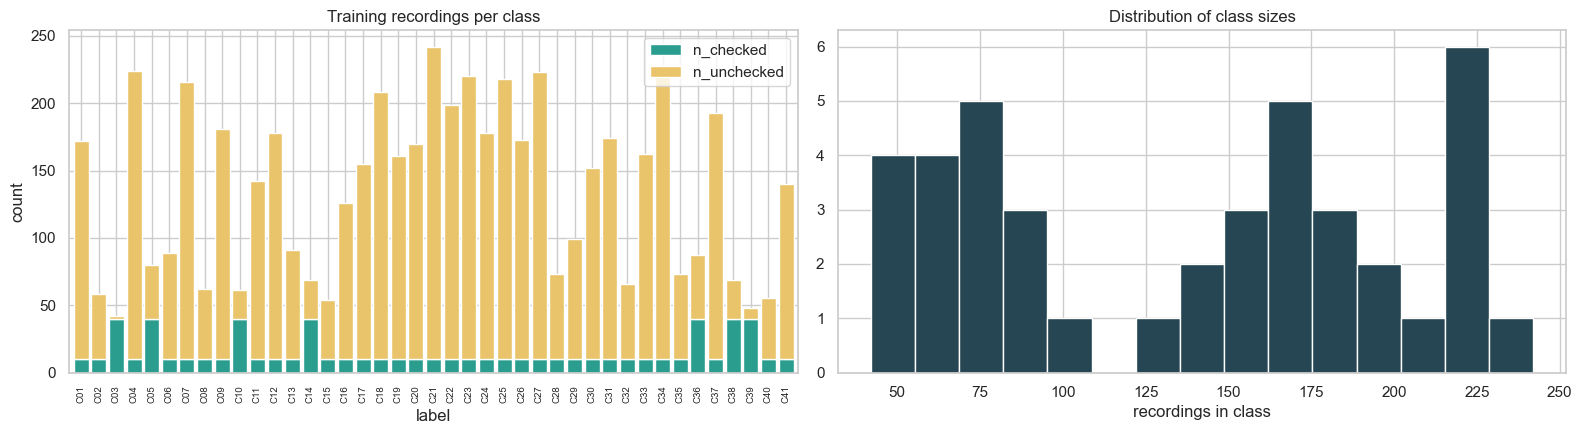

(        n  n_checked  n_unchecked  checked_share
 label                                           
 C03    42         40            2       0.952381
 C39    48         40            8       0.833333
 C15    54         10           44       0.185185
 C40    55         10           45       0.181818
 C02    58         10           48       0.172414,
          n  n_checked  n_unchecked  checked_share
 label                                            
 C23    220         10          210       0.045455
 C34    221         10          211       0.045249
 C27    223         10          213       0.044843
 C04    224         10          214       0.044643
 C21    242         10          232       0.041322)

In [4]:
ct = (train.groupby("label").agg(n=("id","size"), n_checked=("checked","sum")).assign(n_unchecked=lambda d: d.n-d.n_checked))
ct["checked_share"] = ct.n_checked/ct.n
print(ct.n_checked.describe()[["min","max"]].to_dict(), "<- checked per class should be constant")
print("class size: min %d, median %d, max %d, ratio max/min %.1f" % (ct.n.min(), ct.n.median(), ct.n.max(), ct.n.max()/ct.n.min()))

fig, ax = plt.subplots(1, 2, figsize=(16,4.5))
ct[["n_checked","n_unchecked"]].plot(kind="bar", stacked=True, ax=ax[0], width=.85, color=["#2a9d8f","#e9c46a"])
ax[0].set_title("Training recordings per class"); ax[0].set_ylabel("count"); ax[0].tick_params(axis="x", labelsize=7)
ax[1].hist(ct.n, bins=15, color="#264653"); ax[1].set_title("Distribution of class sizes"); ax[1].set_xlabel("recordings in class")
plt.tight_layout(); plt.show()
ct.sort_values("n").head(), ct.sort_values("n").tail()

**Notes.** Every class has the same number of checked recordings, so the *unchecked* pool carries the class imbalance. Since test labels are all checked (and the test class prior is therefore likely close to uniform, like the checked set), the training prior (`n` per class) may be **misleading** for test. Worth considering prior correction / balanced weighting.

## 2. Audio metadata (sample rate, length, loudness)

In [5]:
def meta(p):
    info = sf.info(p)
    return info.samplerate, info.frames, info.channels, info.subtype

m_tr = Parallel(n_jobs=-1)(delayed(meta)(p) for p in train.path)
m_te = Parallel(n_jobs=-1)(delayed(meta)(p) for p in test.path)
for df, m in [(train, m_tr), (test, m_te)]:
    df[["sr","frames","channels","subtype"]] = pd.DataFrame(m, index=df.index)
    df["dur"] = df.frames/df.sr
print("sample rates:", train.sr.unique(), test.sr.unique())
print("channels:", train.channels.unique(), "| subtype:", train.subtype.unique())
SR = int(train.sr.iloc[0])
print("SR =", SR)
display(pd.concat([train.dur.describe().rename("train"), test.dur.describe().rename("test")], axis=1).T)

sample rates: [22050] [22050]
channels: [1] | subtype: <ArrowStringArray>
['PCM_16']
Length: 1, dtype: str
SR = 22050


,count,mean,std,min,25%,50%,75%,max
train,5604.0,7.880497,7.566021,0.375329,2.023095,4.932880,11.360113,31.437823
test,1592.0,5.491405,5.413073,0.417279,1.769796,3.786349,7.193515,30.876463


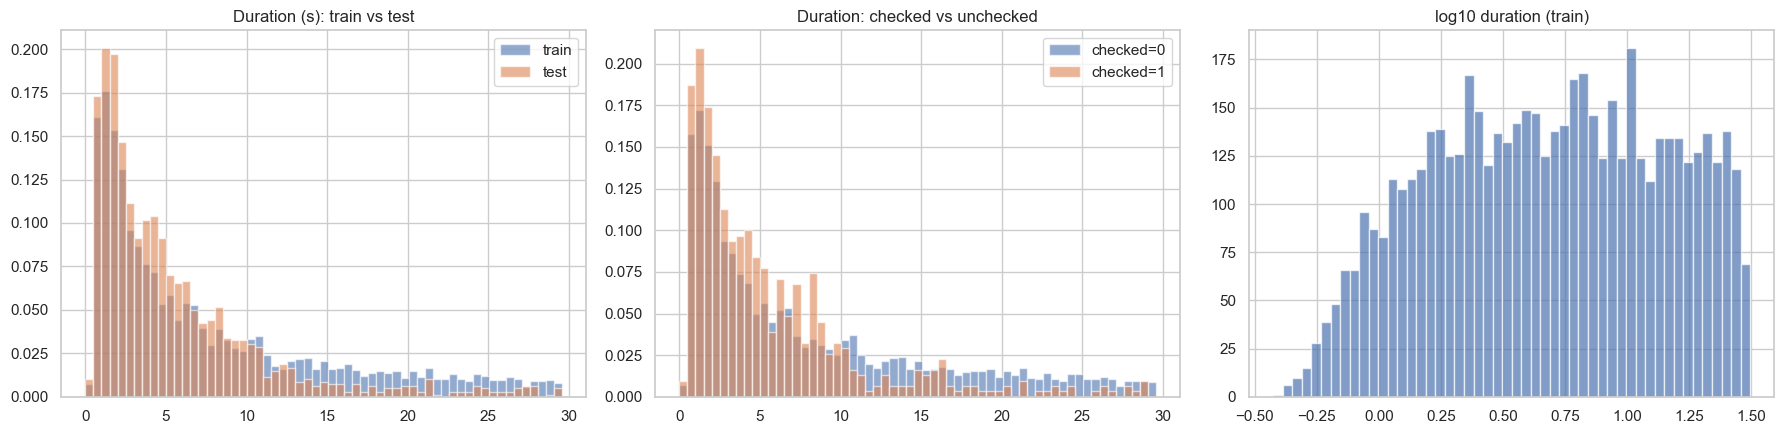

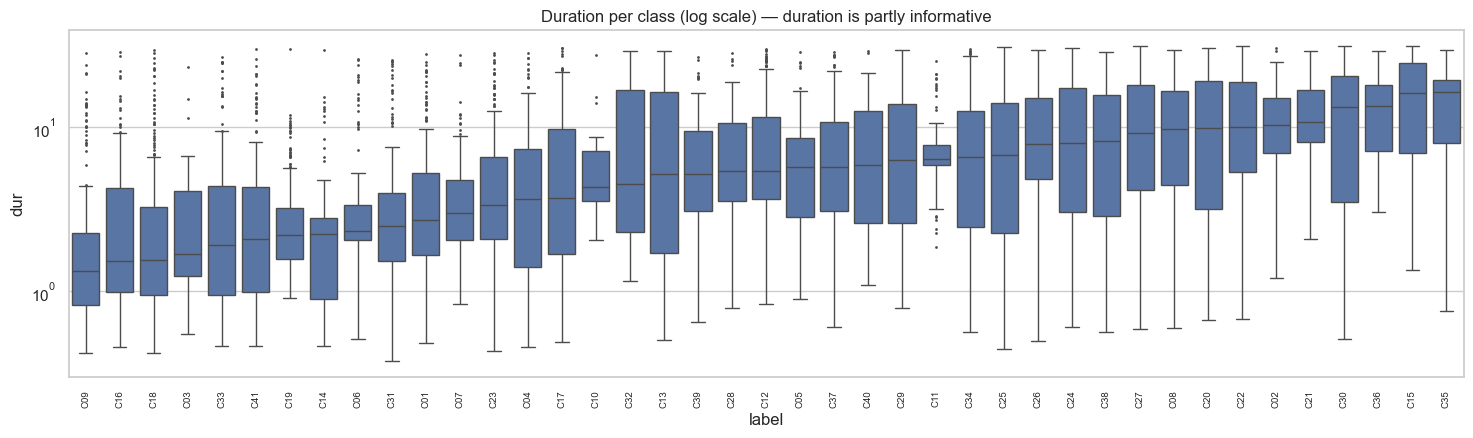

fraction of clips with the modal duration (~constant length?):
dur
1.04    18
0.87    18
1.20    17
0.79    17
1.18    17
Name: count, dtype: int64


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18,4.5))
bins = np.linspace(0, train.dur.quantile(.995), 60)
ax[0].hist(train.dur, bins, alpha=.6, density=True, label="train"); ax[0].hist(test.dur, bins, alpha=.6, density=True, label="test")
ax[0].set_title("Duration (s): train vs test"); ax[0].legend()
for c, g in train.groupby("checked"): ax[1].hist(g.dur, bins, alpha=.6, density=True, label=f"checked={c}")
ax[1].set_title("Duration: checked vs unchecked"); ax[1].legend()
ax[2].hist(np.log10(train.dur), 50, alpha=.7); ax[2].set_title("log10 duration (train)")
plt.tight_layout(); plt.show()

# duration per class
order = train.groupby("label").dur.median().sort_values().index
plt.figure(figsize=(18,4.5)); sns.boxplot(data=train, x="label", y="dur", order=order, fliersize=1)
plt.xticks(rotation=90, fontsize=7); plt.yscale("log"); plt.title("Duration per class (log scale) — duration is partly informative"); plt.show()
print("fraction of clips with the modal duration (~constant length?):")
print(train.dur.round(2).value_counts().head(5))

## 3. Listening-free inspection: waveforms and spectrograms

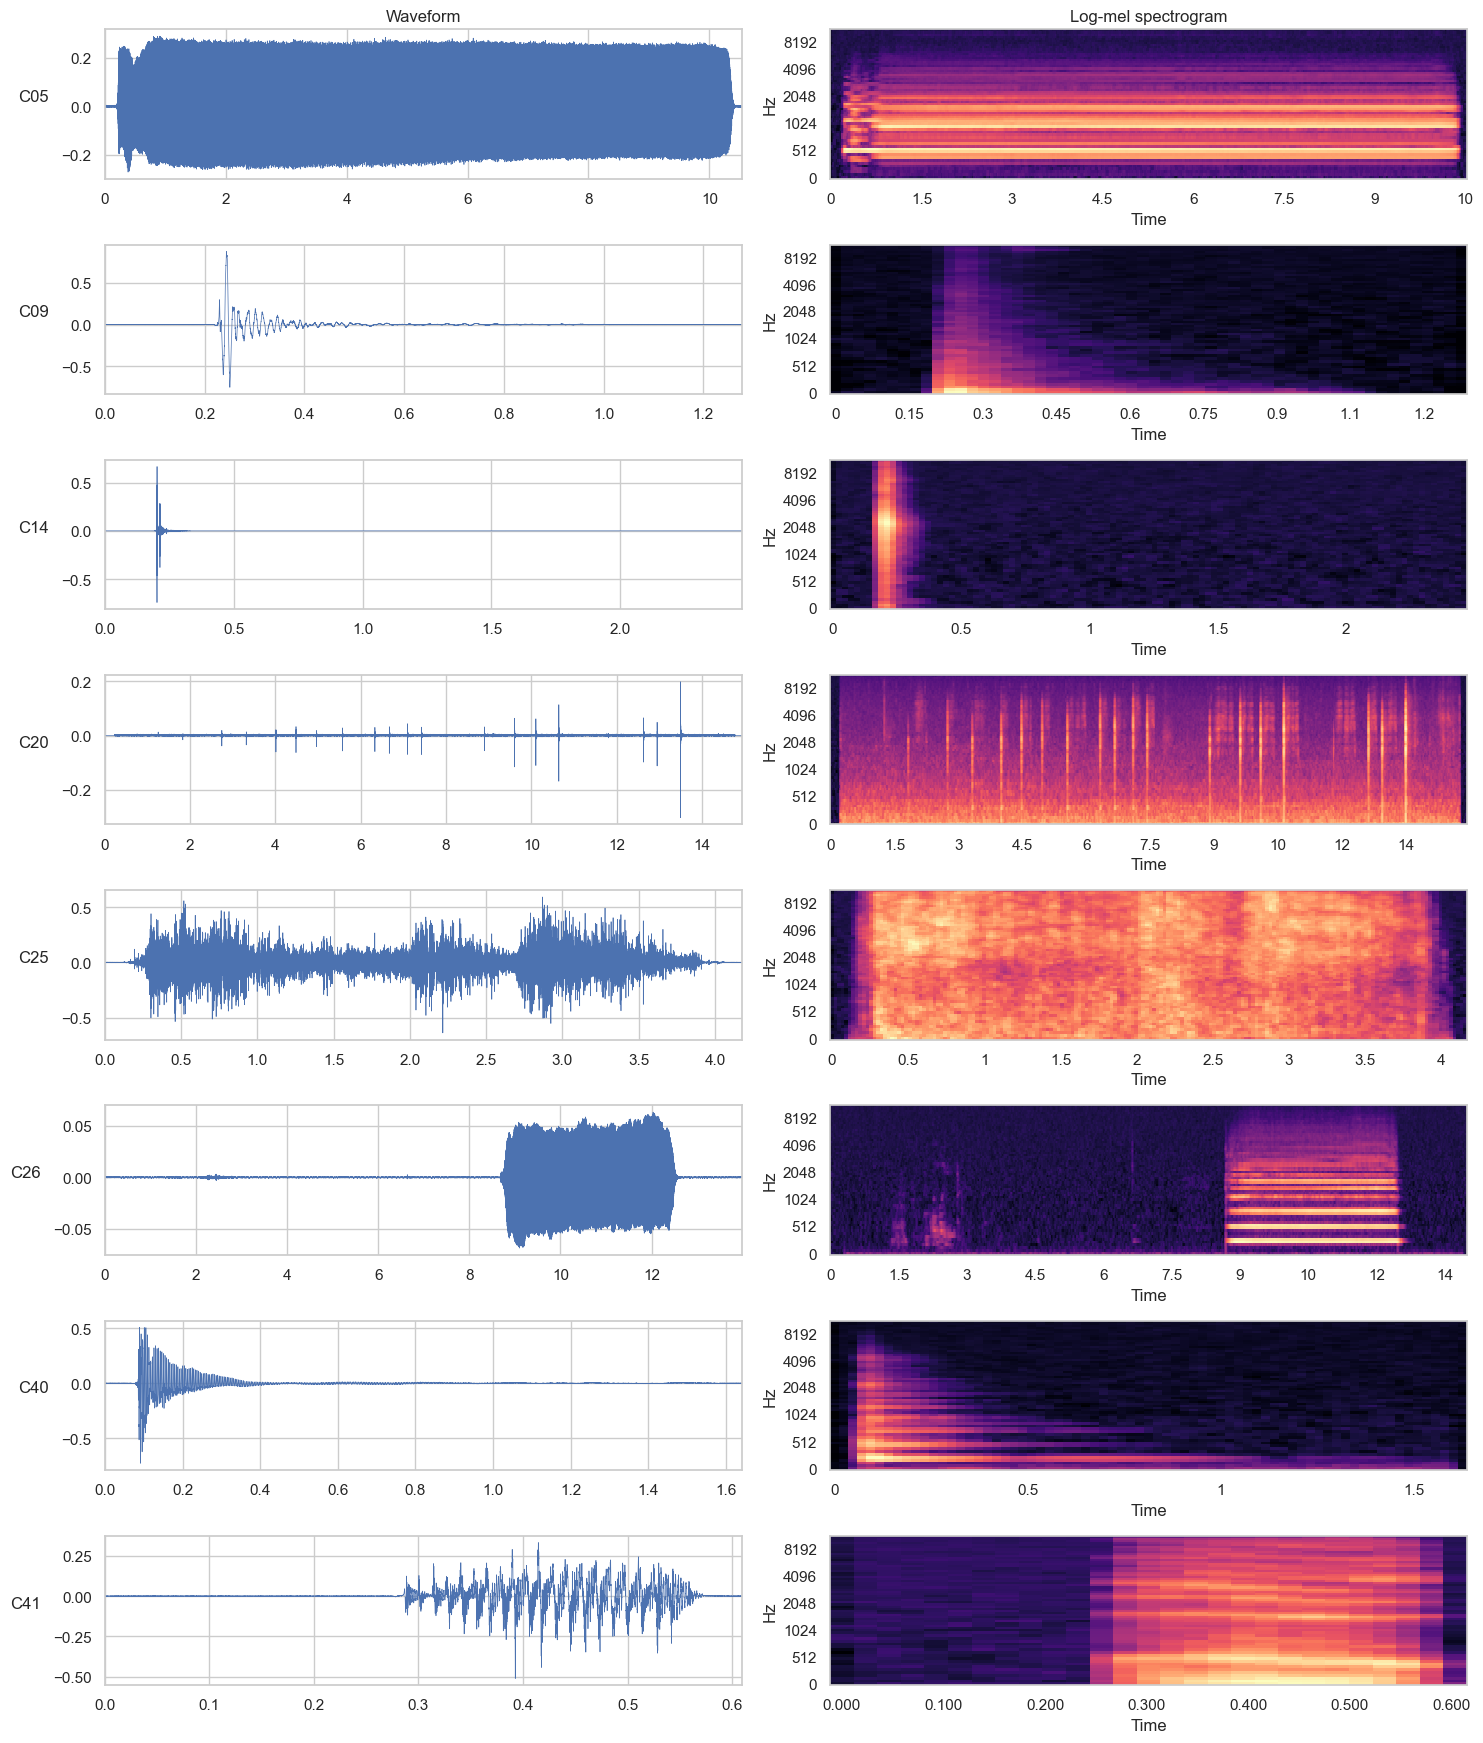

In [7]:
def load(p): 
    y, sr = sf.read(p, dtype="float32"); 
    return y if y.ndim==1 else y.mean(1), sr

classes = sorted(train.label.unique())
rng = np.random.RandomState(RNG)
show = rng.choice(classes, 8, replace=False)
fig, axes = plt.subplots(len(show), 2, figsize=(15, 2.2*len(show)))
for r, c in enumerate(sorted(show)):
    row = train[(train.label==c)&(train.checked==1)].sample(1, random_state=RNG).iloc[0]   # use a *checked* example
    y, sr = load(row.path)
    t = np.arange(len(y))/sr
    axes[r,0].plot(t, y, lw=.5); axes[r,0].set_ylabel(c, rotation=0, labelpad=20); axes[r,0].set_xlim(0, max(t[-1], .1))
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=np.pad(y,(0,max(0,2048-len(y)))), sr=sr, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="mel", ax=axes[r,1])
axes[0,0].set_title("Waveform"); axes[0,1].set_title("Log-mel spectrogram")
plt.tight_layout(); plt.show()

## 4. Clip-level features for the whole dataset
Compute loudness / silence / clipping statistics and a compact timbre descriptor (MFCC + spectral stats, mean & std). Cached to disk.

In [8]:
N_MFCC, N_MELS = 20, 64
def feats(p):
    y, sr = load(p)
    n = len(y)
    f = {"peak": float(np.abs(y).max()) if n else 0, "clip_frac": float((np.abs(y)>=0.999).mean()) if n else 0, "dc": float(y.mean()) if n else 0}
    yp = np.pad(y, (0, max(0, 4096-n)))
    rms = librosa.feature.rms(y=yp)[0]
    f["rms_mean"], f["rms_std"] = rms.mean(), rms.std()
    f["silence_frac"] = float((rms < 1e-3).mean())                       # absolute silence
    f["rel_silence_frac"] = float((rms < 0.1*rms.max()+1e-12).mean())    # relative to loudest frame
    f["zcr"] = librosa.feature.zero_crossing_rate(yp).mean()
    S = np.abs(librosa.stft(yp, n_fft=1024))**2
    mel = librosa.power_to_db(librosa.feature.melspectrogram(S=S, sr=sr, n_mels=N_MELS))
    mf = librosa.feature.mfcc(S=mel, n_mfcc=N_MFCC)
    cen = librosa.feature.spectral_centroid(S=np.sqrt(S), sr=sr)[0]
    bw  = librosa.feature.spectral_bandwidth(S=np.sqrt(S), sr=sr)[0]
    ro  = librosa.feature.spectral_rolloff(S=np.sqrt(S), sr=sr)[0]
    f["centroid"], f["bandwidth"], f["rolloff"] = cen.mean(), bw.mean(), ro.mean()
    d = {**f}
    for i in range(N_MFCC): d[f"mfcc{i}_m"], d[f"mfcc{i}_s"] = mf[i].mean(), mf[i].std()
    for i in range(N_MELS): d[f"mel{i}_m"] = mel[i].mean()
    return d

CACHE = f"{OUT_DIR}/eda_feats.pkl"
if os.path.exists(CACHE):
    F = pd.read_pickle(CACHE)
else:
    allp = list(train.path) + list(test.path)
    F = pd.DataFrame(Parallel(n_jobs=-1, batch_size=32)(delayed(feats)(p) for p in allp))
    F.to_pickle(CACHE)
Ftr, Fte = F.iloc[:len(train)].reset_index(drop=True), F.iloc[len(train):].reset_index(drop=True)
print(Ftr.shape, Fte.shape, "| any NaN:", F.isna().any().any())

(5604, 115) (1592, 115) | any NaN: False


### 4.1 Loudness, silence, clipping — train vs test and checked vs unchecked

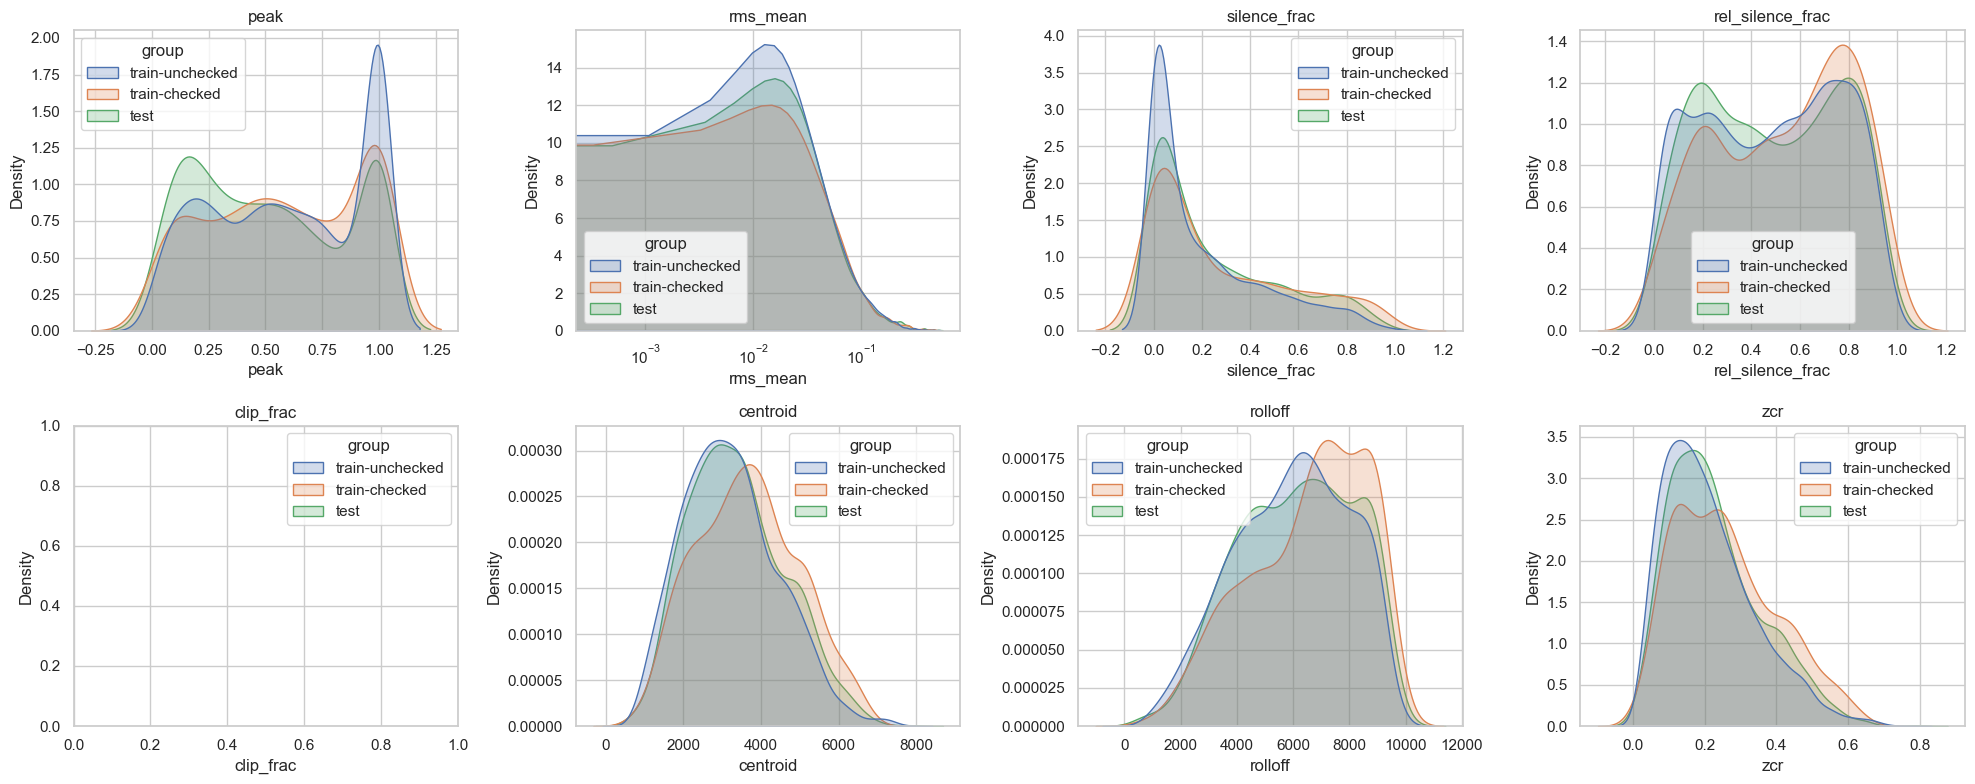

clips with >50% silent frames: train 15.5% | test 20.5%
clips with any clipping: train 0.0% | test 0.0%
near-silent clips (rms_mean<1e-3): train 73 | test 28


In [9]:
basic = ["peak","rms_mean","silence_frac","rel_silence_frac","clip_frac","centroid","rolloff","zcr"]
tmp = pd.concat([Ftr[basic].assign(group=np.where(train.checked==1,"train-checked","train-unchecked")),
                 Fte[basic].assign(group="test")])
fig, axes = plt.subplots(2, 4, figsize=(20,8))
for a, c in zip(axes.ravel(), basic):
    sns.kdeplot(data=tmp, x=c, hue="group", common_norm=False, fill=True, alpha=.25, ax=a, warn_singular=False)
    a.set_title(c)
    if c in ("rms_mean",): a.set_xscale("log")
plt.tight_layout(); plt.show()
print("clips with >50%% silent frames: train %.1f%% | test %.1f%%" % (100*(Ftr.silence_frac>.5).mean(), 100*(Fte.silence_frac>.5).mean()))
print("clips with any clipping: train %.1f%% | test %.1f%%" % (100*(Ftr.clip_frac>0).mean(), 100*(Fte.clip_frac>0).mean()))
print("near-silent clips (rms_mean<1e-3): train", int((Ftr.rms_mean<1e-3).sum()), "| test", int((Fte.rms_mean<1e-3).sum()))

In [10]:
# Covariate shift check: can a classifier tell train from test? (AUC ~0.5 => same distribution)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
X_adv = pd.concat([Ftr, Fte]).values; y_adv = np.r_[np.zeros(len(Ftr)), np.ones(len(Fte))]
auc = cross_val_score(HistGradientBoostingClassifier(max_iter=150), X_adv, y_adv, cv=5, scoring="roc_auc")
print("adversarial train-vs-test AUC: %.3f +/- %.3f" % (auc.mean(), auc.std()))
Xc = Ftr.assign(dur=train.dur).values; yc = train.checked.values
auc2 = cross_val_score(HistGradientBoostingClassifier(max_iter=150), Xc, yc, cv=5, scoring="roc_auc")
print("checked-vs-unchecked AUC: %.3f  (>0.5 => checked subset is not a random sample / label noise leaks into features)" % auc2.mean())

adversarial train-vs-test AUC: 0.645 +/- 0.013
checked-vs-unchecked AUC: 0.700  (>0.5 => checked subset is not a random sample / label noise leaks into features)


## 5. How noisy are the unchecked labels?
We can't see which labels are wrong, but the **checked** subset is clean. Train on it, and measure how often the model agrees with the *given* label of unchecked clips, per class.

`agreement ≈ (1 − noise) · clean_accuracy + noise · (small)`, so `noise ≈ 1 − agreement / clean_accuracy` (rough estimate).

In [11]:
feat_cols = [c for c in Ftr.columns if c not in ("dc",)]
X = Ftr[feat_cols].assign(dur=np.log1p(train.dur)).values
y = train.label.values
chk = train.checked.values==1
cls = np.array(classes)

def make(): return ExtraTreesClassifier(n_estimators=500, min_samples_leaf=1, n_jobs=-1, random_state=RNG, class_weight="balanced")

# (a) clean accuracy by CV on checked only
skf = StratifiedKFold(5, shuffle=True, random_state=RNG)
P_chk = cross_val_predict(make(), X[chk], y[chk], cv=skf, method="predict_proba")
clean_acc = (cls[P_chk.argmax(1)] == y[chk]).mean()
print("n checked per class:", chk.sum()//len(cls), "| CV accuracy on checked only: %.3f" % clean_acc)

# (b) fit on all checked, predict unchecked
m = make().fit(X[chk], y[chk])
P_unc = m.predict_proba(X[~chk])
pred_unc = cls[P_unc.argmax(1)]
agree = (pred_unc == y[~chk])
print("overall agreement model vs given label on UNCHECKED: %.3f" % agree.mean())

n checked per class: 15 | CV accuracy on checked only: 0.508
overall agreement model vs given label on UNCHECKED: 0.236


rough overall noise estimate: 0.35


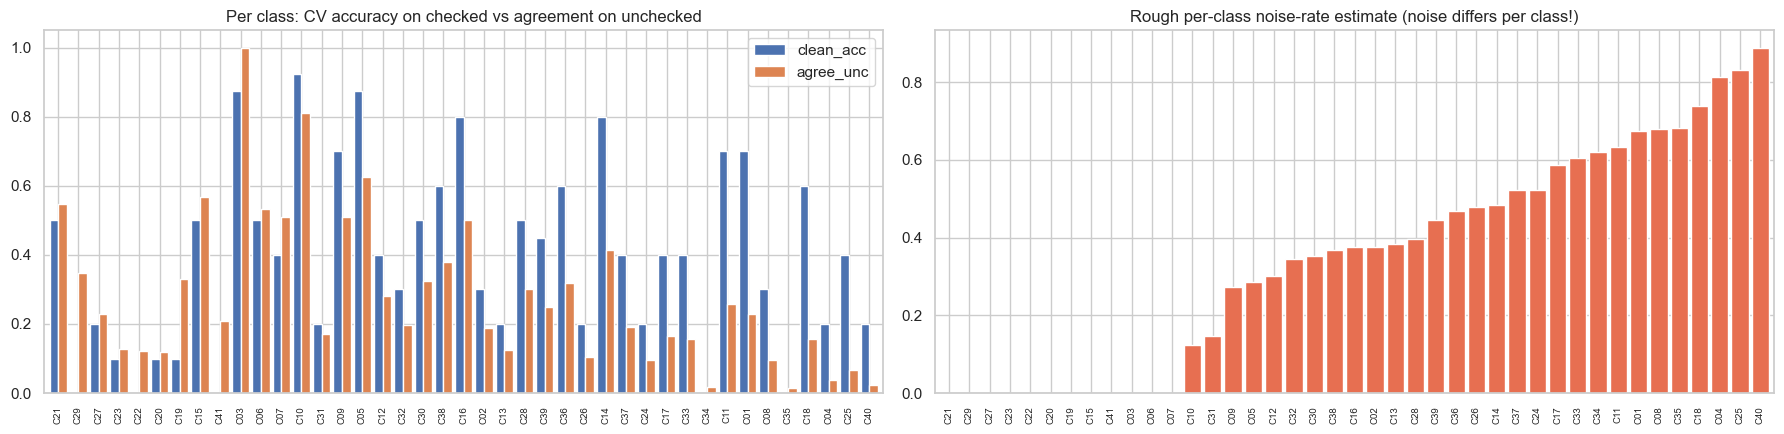

,clean_acc,agree_unc,n_unc,noise_est
C40,0.2,0.022222,45,0.888889
C25,0.4,0.067308,208,0.831731
C04,0.2,0.037383,214,0.813084
C18,0.6,0.156566,198,0.739057
C35,0.0,0.015873,63,0.682540
C08,0.3,0.096154,52,0.679487
C01,0.7,0.228395,162,0.673721
C11,0.7,0.257576,132,0.632035


In [12]:
per = pd.DataFrame({
    "clean_acc": pd.Series(cls[P_chk.argmax(1)] == y[chk]).groupby(y[chk]).mean(),
    "agree_unc": pd.Series(agree).groupby(y[~chk]).mean(),
    "n_unc": pd.Series(y[~chk]).value_counts(),
})
per["noise_est"] = (1 - per.agree_unc/per.clean_acc.clip(lower=.05)).clip(0, 1)
print("rough overall noise estimate: %.2f" % (per.noise_est*per.n_unc).sum().__truediv__(per.n_unc.sum()))
fig, ax = plt.subplots(1, 2, figsize=(18,4.5))
per.sort_values("noise_est")[["clean_acc","agree_unc"]].plot(kind="bar", ax=ax[0], width=.85); ax[0].tick_params(axis="x", labelsize=7)
ax[0].set_title("Per class: CV accuracy on checked vs agreement on unchecked")
per.sort_values("noise_est").noise_est.plot(kind="bar", ax=ax[1], color="#e76f51", width=.85); ax[1].tick_params(axis="x", labelsize=7)
ax[1].set_title("Rough per-class noise-rate estimate (noise differs per class!)")
plt.tight_layout(); plt.show()
per.sort_values("noise_est", ascending=False).head(8)

corr(noise_est, class size): -0.01


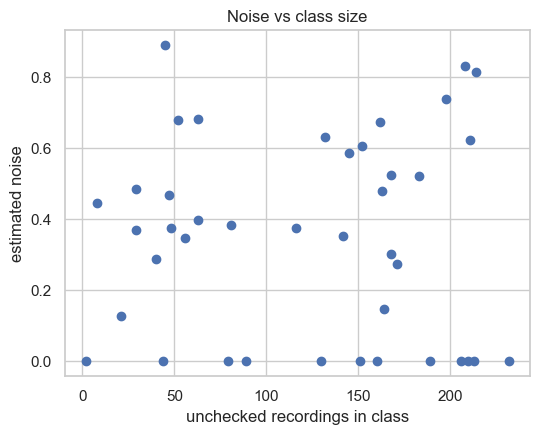

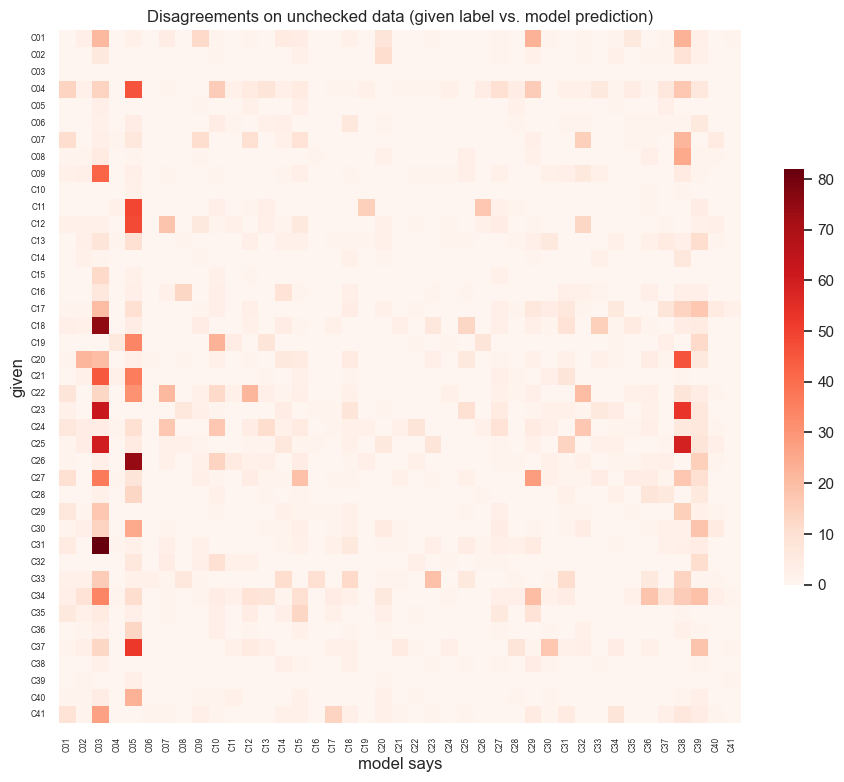

In [13]:
# Is noise related to class size? (noisy classes often get "dumped" into / drawn from big classes)
print("corr(noise_est, class size): %.2f" % per.noise_est.corr(per.n_unc))
plt.figure(figsize=(6,4.5)); plt.scatter(per.n_unc, per.noise_est); plt.xlabel("unchecked recordings in class"); plt.ylabel("estimated noise"); plt.title("Noise vs class size"); plt.show()

# Where do the mislabeled clips go? Confusion: given label -> model's prediction, on disagreeing unchecked clips
dis = pd.crosstab(pd.Series(y[~chk][~agree], name="given"), pd.Series(pred_unc[~agree], name="model says"))
plt.figure(figsize=(11,9)); sns.heatmap(dis.reindex(index=classes, columns=classes, fill_value=0), cmap="Reds", cbar_kws={"shrink":.6})
plt.title("Disagreements on unchecked data (given label vs. model prediction)"); plt.xticks(fontsize=6); plt.yticks(fontsize=6); plt.show()

### 5.1 Confidence of the model on the given label (a cleaning signal)

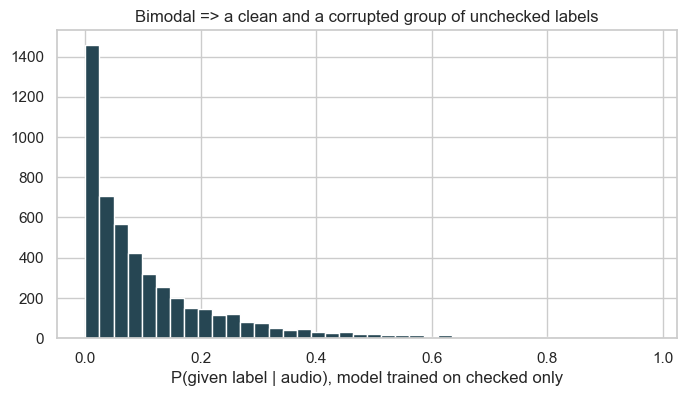

share of unchecked with p_given < 0.05: 0.43


In [14]:
idx = {c:i for i,c in enumerate(cls)}
p_given = P_unc[np.arange(len(P_unc)), [idx[c] for c in y[~chk]]]
plt.figure(figsize=(8,4)); plt.hist(p_given, 40, color="#264653"); plt.xlabel("P(given label | audio), model trained on checked only")
plt.title("Bimodal => a clean and a corrupted group of unchecked labels"); plt.show()
print("share of unchecked with p_given < 0.05: %.2f" % (p_given<.05).mean())

## 6. Low-dimensional view

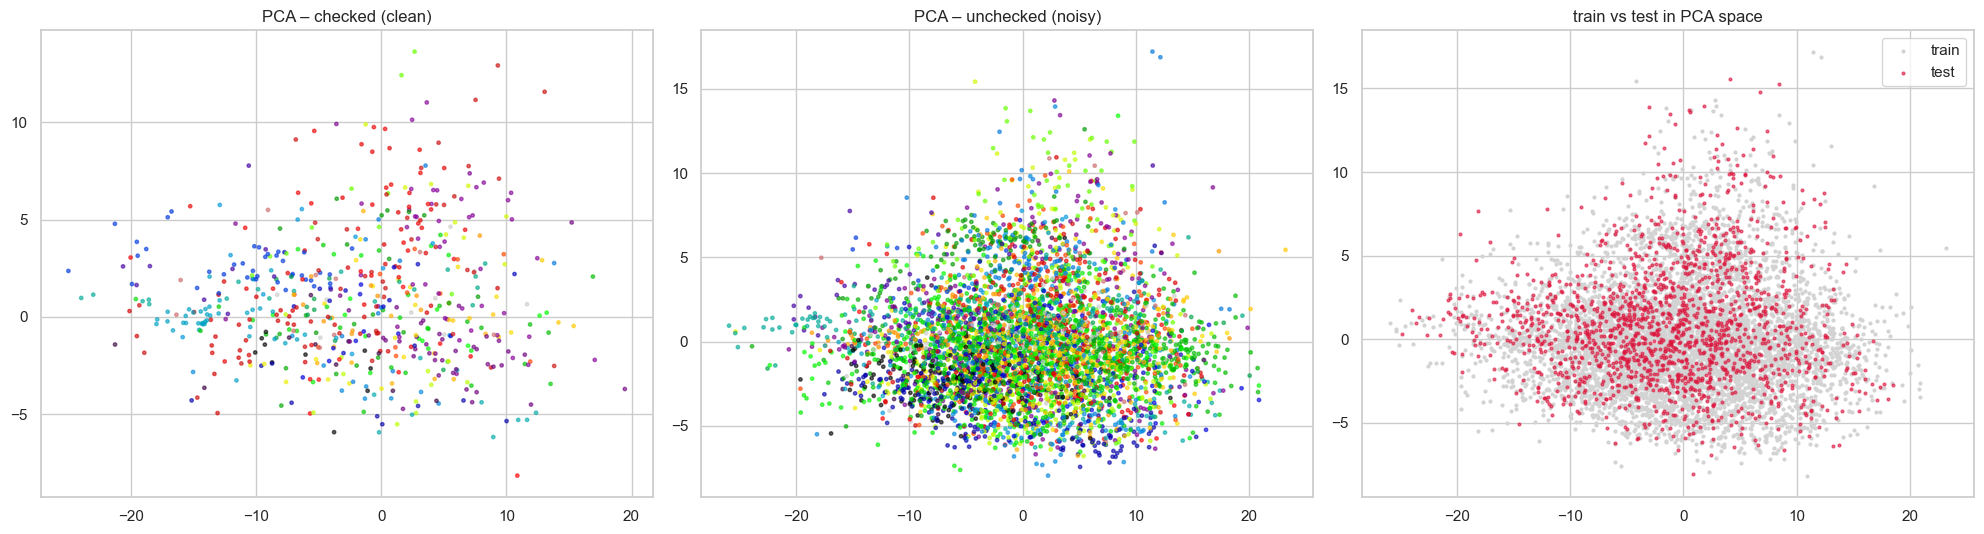

components for 90% variance: 18 of 115


In [15]:
Xs = StandardScaler().fit_transform(X)
Z = PCA(2, random_state=RNG).fit_transform(Xs)
fig, ax = plt.subplots(1, 3, figsize=(20,5.5))
for a, (mask, t) in zip(ax[:2], [(chk,"checked (clean)"), (~chk,"unchecked (noisy)")]):
    sc = a.scatter(Z[mask,0], Z[mask,1], c=pd.factorize(y[mask], sort=True)[0], cmap="nipy_spectral", s=6, alpha=.6); a.set_title("PCA – "+t)
ax[2].scatter(Z[:,0], Z[:,1], s=4, c="lightgrey", label="train"); Zt = PCA(2, random_state=RNG).fit(Xs).transform(StandardScaler().fit(X).transform(Fte[feat_cols].assign(dur=np.log1p(test.dur)).values))
ax[2].scatter(Zt[:,0], Zt[:,1], s=4, c="crimson", alpha=.6, label="test"); ax[2].legend(); ax[2].set_title("train vs test in PCA space")
plt.tight_layout(); plt.show()
pca = PCA().fit(Xs); print("components for 90%% variance: %d of %d" % (np.searchsorted(np.cumsum(pca.explained_variance_ratio_), .9)+1, Xs.shape[1]))

## 7. Baseline MAP@3 on the clean (checked) subset

In [16]:
def map3(P, true, classes=cls):
    top = np.argsort(-P, 1)[:, :3]
    true_i = np.array([list(classes).index(t) for t in true])
    hit = top == true_i[:,None]
    return (hit / np.arange(1,4)).sum(1).mean()

print("MAP@3, ExtraTrees on handcrafted clip features, 5-fold CV on checked only: %.3f" % map3(P_chk, y[chk]))
# does adding unchecked data (naively) help or hurt? evaluate always on held-out *checked* folds
res = {"checked only":[], "checked + all unchecked (naive)":[], "checked + unchecked with p_given>0.2":[]}
ci = np.where(chk)[0]; ui = np.where(~chk)[0]
keep_u = ui[p_given > .2]
for tr, va in skf.split(ci, y[ci]):
    tr_c, va_c = ci[tr], ci[va]
    for name, tr_idx in [("checked only", tr_c), ("checked + all unchecked (naive)", np.r_[tr_c, ui]), ("checked + unchecked with p_given>0.2", np.r_[tr_c, keep_u])]:
        mm = make().fit(X[tr_idx], y[tr_idx]); res[name].append(map3(mm.predict_proba(X[va_c]), y[va_c]))
display(pd.DataFrame(res).agg(["mean","std"]).T)

MAP@3, ExtraTrees on handcrafted clip features, 5-fold CV on checked only: 0.591


,mean,std
checked only,0.590591,0.021644
checked + all unchecked (naive),0.593817,0.021239
checked + unchecked with p_given>0.2,0.643548,0.023171


## 8. Summary of findings & modelling implications

Fill in after running — typical things to confirm from the outputs above:

| Observation | Implication |
|---|---|
| Same number of checked clips per class, class sizes differ a lot (via the unchecked pool) | Test is likely ~balanced; use balanced class weights / prior correction, stratified CV on checked clips |
| Sample rate constant; durations vary widely (≈ log-normal) | Fixed-length crops are wasteful; use clip-level statistics (mean/std over frames), GMM over frames, or pad/segment |
| Silence & background noise present in many clips | Use energy-based frame selection / robust statistics; relative-silence feature |
| Train and test have similar feature distributions (adversarial AUC ≈ 0.5) | No covariate shift; checked-set CV is a trustworthy validation proxy |
| Noise rate differs across classes (Section 5) | Per-class noise modelling (EM over true label with a class-conditional transition matrix), not one global noise rate |
| Model-confidence on given label is bimodal | Cross-validated filtering / soft re-weighting of unchecked samples is promising |
| Naive use of unchecked labels vs checked only (Section 7) | Quantifies how much the noise hurts and how much cleaning helps |

**Next steps:** richer frame-level features (log-mel, MFCC + deltas, chroma, contrast), GMM-supervector / bag-of-frames, SVM-RBF + LightGBM + kNN ensemble, noisy-label EM / co-teaching-style filtering with out-of-fold probabilities, self-training on unchecked, and always validate on **held-out checked** clips only (that is what the test set looks like).